# Phase 10 — Cold-start / unseen-SKU forecasting (Use Case 4)

คำถาม: โมเดลที่ไม่เคยเห็น SKU นี้มาก่อนพยากรณ์ได้ดีแค่ไหนเมื่อเริ่มมีประวัติขาย?

ทดสอบ 5 SKU เปิดตัวล่าสุด: YO-024, MI-008, SN-028, YO-018, SN-030
กันทั้ง 5 SKU ออกจาก train ทุกครั้ง ฝึกโมเดลแยกตาม cutoff ก่อนเปิดตัวแต่ละ SKU
และคงโมเดลไว้ตลอดการทดสอบ (ไม่ retrain) เปรียบเทียบ analog, meta-learner และ full model
บนแถวเดียวกันที่ทุกวิธีมี prediction โดยรายงาน coverage เพิ่มเติม


In [1]:
import sys
sys.path.insert(0, '../../src')

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from models.cold_start import analog_forecast, meta_learner_forecast, mature_model_forecast
from models.metrics import score_all

pd.set_option('display.width', 160)

df = pd.read_csv('../../data/processed/weekly_features.csv', parse_dates=['week'])
daily = pd.read_csv('../../data/raw/FMCG_2022_2024.csv', parse_dates=['date'])
sku_attrs = daily.groupby('sku').agg(
    pack_type=('pack_type', 'first'), segment=('segment', 'first'),
    category=('category', 'first'), price_unit=('price_unit', 'mean'),
    first_seen=('date', 'min'),
)

COLD_START_SKUS = ['YO-024', 'MI-008', 'SN-028', 'YO-018', 'SN-030']
print('Cold-start validation SKUs:', COLD_START_SKUS)


Cold-start validation SKUs: ['YO-024', 'MI-008', 'SN-028', 'YO-018', 'SN-030']


## ขอบเขตและข้อมูลที่ใช้ได้

ตารางนี้เริ่มที่ sku_age=4 เพราะต้องมี rolling history ครบ 4 สัปดาห์ก่อนหน้า
จึงเป็น **short-history / unseen-SKU** ไม่ใช่ zero-history หรือการทำนายก่อนเริ่มขาย
Meta-learner ตัด lag ออกแต่ยังใช้ยอดขายสัปดาห์ปัจจุบันและ demand share ที่ทราบเมื่อจบสัปดาห์
Full model ใช้ประวัติของ SKU ทดสอบ ณ สัปดาห์พยากรณ์ แต่ไม่ใช้ SKU เหล่านั้นฝึกโมเดล

cutoff คือวันจันทร์ของสัปดาห์เปิดตัว (ก่อน first_seen)
แถวฝึกที่ week=W มี label ยอดขายสัปดาห์ W+7 ถึง W+14 จึงใช้ได้เมื่อ W+14 <= cutoff เท่านั้น
โมเดล ML ใช้ vocabulary ของ categorical จาก train เท่านั้น


## 1. Analog-Based Forecast


Analog จับคู่ category+segment แล้วผ่อนเป็น category และราคา ตามลำดับ
ไม่ใช้ pack_type เพราะเปลี่ยนภายใน SKU ใช้ราคาเฉลี่ย candidate จากข้อมูลก่อน cutoff เท่านั้น
ราคา target ใช้ราคาเฉลี่ยวันแรกที่ขายเป็น **proxy ของราคาเปิดตัว** ไม่ใช่หลักฐานว่ารู้อยู่ก่อนเปิดตัว
Analog ใช้ target_next_week ที่อายุเดียวกัน และเฉพาะ trajectory ที่ label ครบก่อน cutoff
จึงอาจไม่มี prediction เมื่ออายุเพิ่มขึ้น ไม่มีการเติมผลจากข้อมูลหลัง cutoff


In [2]:
analog_df = analog_forecast(df, COLD_START_SKUS, sku_attrs, daily=daily)
print(analog_df[['sku', 'analog_sku', 'train_cutoff']].drop_duplicates().to_string(index=False))
print(f'Analog coverage: {analog_df.pred_analog.notna().mean():.1%}')


   sku analog_sku train_cutoff
MI-008     MI-022   2023-04-10
SN-028     SN-019   2023-04-17
SN-030     SN-019   2023-05-22
YO-018     YO-001   2023-05-01
YO-024     YO-016   2023-04-03
Analog coverage: 24.2%


## 2. Meta-Learner Forecast (ตัด lag/rolling ออก แต่ยังใช้ยอดขายสัปดาห์ปัจจุบัน)


In [3]:
meta_df = meta_learner_forecast(df, COLD_START_SKUS)


## 3. Full Model Forecast (มีฟีเจอร์ lag ครบ, ใช้เป็นตัวเทียบ)


In [4]:
full_df = mature_model_forecast(df, COLD_START_SKUS)


## 4. เปรียบเทียบผลตามอายุสินค้า

แสดงอายุจริง sku_age (เริ่มที่ 4) และรวมอายุ >=24 เป็น 24+ อย่างชัดเจน
ทุกวิธีใช้แถวเดียวกันในแต่ละช่วง พร้อมจำนวนแถวและ analog coverage
แถวที่ analog ไม่มี prediction ไม่อยู่ในตารางเปรียบเทียบ แต่รายงานผล ML บนทุกแถวแยกท้าย notebook
ไม่ใช้เส้น Phase 7 เป็นเกณฑ์ตามทัน เพราะคนละ validation protocol


In [5]:
from models.cold_start import launch_week

scored = analog_df[['sku', 'week', 'channel', 'region', 'sku_age', 'target_next_week', 'pred_analog']].copy()
scored['pred_meta_learner'] = meta_df.pred_meta_learner.reindex(scored.index)
scored['pred_full_model'] = full_df.pred_full_model.reindex(scored.index)
pred_cols = ['pred_analog', 'pred_meta_learner', 'pred_full_model']
assert scored[pred_cols[1:]].notna().all().all()
for sku in COLD_START_SKUS:
    cutoff = launch_week(df, sku)
    assert (meta_df.loc[meta_df.sku == sku, 'train_label_available_max'] <= cutoff).all()
    assert (full_df.loc[full_df.sku == sku, 'train_label_available_max'] <= cutoff).all()

scored['age_bucket'] = scored.sku_age.clip(upper=24).astype(int)
common = scored.dropna(subset=pred_cols + ['target_next_week']).copy()
rows = []
for age, available in scored.groupby('age_bucket'):
    shared = common[common.age_bucket == age]
    row = {'sku_age': age, 'age_label': '24+' if age == 24 else str(age),
           'n': len(shared), 'available_n': len(available),
           'coverage': len(shared) / len(available)}
    for label, col in zip(['Analog', 'Meta-learner', 'Full model'], pred_cols):
        row[label] = score_all(shared.target_next_week, shared[col])['WAPE'] if len(shared) else np.nan
    rows.append(row)
curve = pd.DataFrame(rows)
curve.round(3)


,sku_age,age_label,n,available_n,coverage,Analog,Meta-learner,Full model
0,4,4,44,44,1.0,0.276,0.221,0.216
1,5,5,45,45,1.0,0.380,0.242,0.215
2,6,6,45,45,1.0,0.383,0.285,0.267
3,7,7,45,45,1.0,0.460,0.288,0.252
4,8,8,36,45,0.8,0.283,0.306,0.257
5,9,9,36,45,0.8,0.362,0.246,0.228
6,10,10,36,45,0.8,0.277,0.249,0.243
7,11,11,36,45,0.8,0.320,0.293,0.246
8,12,12,36,45,0.8,0.258,0.260,0.246
9,13,13,27,45,0.6,0.348,0.234,0.230


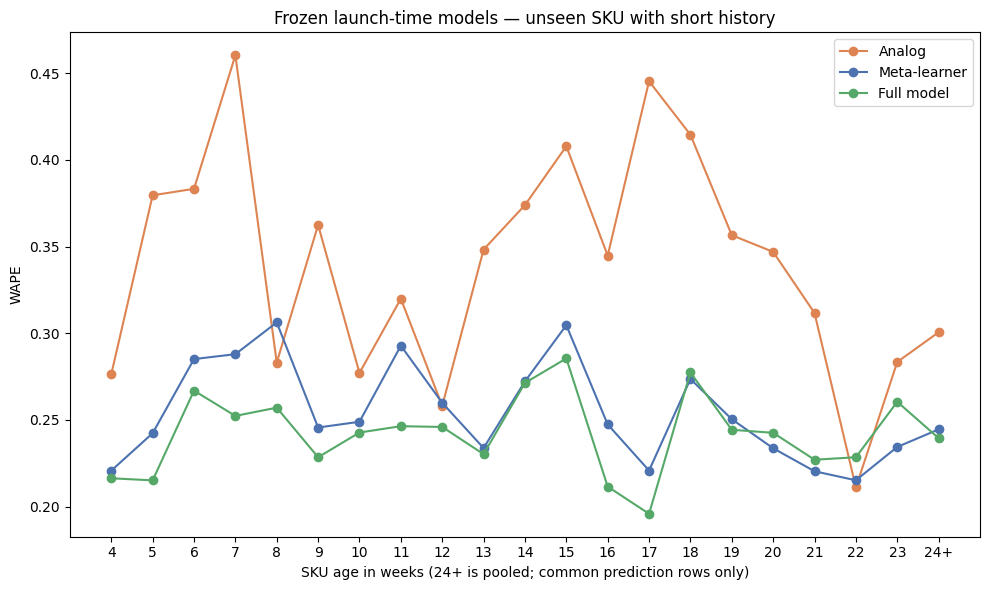

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
for col, color in [('Analog', '#DD8452'), ('Meta-learner', '#4C72B0'), ('Full model', '#55A868')]:
    ax.plot(curve.sku_age, curve[col], marker='o', label=col, color=color)
ax.set_xticks(curve.sku_age)
ax.set_xticklabels(curve.age_label)
ax.set_xlabel('SKU age in weeks (24+ is pooled; common prediction rows only)')
ax.set_ylabel('WAPE')
ax.set_title('Frozen launch-time models — unseen SKU with short history')
ax.legend()
plt.tight_layout()
plt.savefig('../../reports/figures/phase10_cold_start_curve.png', dpi=120)
plt.show()


## 5. ผลสรุปบนแถวเดียวกัน

ช่วงอายุ 4–11 เทียบกับ 12+ (ไม่ใช่สัปดาห์แรกก่อนมีประวัติ)
coverage ต่ำหมายถึงผลเป็นเพียง subset และใช้สรุปแทนทุกแถวไม่ได้


In [7]:
summary_rows = []
for label, lower, upper in [('age 4-11 (short history)', 4, 12), ('age 12+', 12, np.inf)]:
    available = scored[(scored.sku_age >= lower) & (scored.sku_age < upper)]
    shared = common[(common.sku_age >= lower) & (common.sku_age < upper)]
    row = {'window': label, 'n': len(shared), 'available_n': len(available),
           'coverage': len(shared) / len(available)}
    for name, col in zip(['Analog WAPE', 'Meta-learner WAPE', 'Full model WAPE'], pred_cols):
        row[name] = score_all(shared.target_next_week, shared[col])['WAPE'] if len(shared) else np.nan
    summary_rows.append(row)
summary = pd.DataFrame(summary_rows)
summary.round(3)


,window,n,available_n,coverage,Analog WAPE,Meta-learner WAPE,Full model WAPE
0,age 4-11 (short history),323,359,0.900,0.344,0.269,0.242
1,age 12+,594,3427,0.173,0.327,0.248,0.242


## 6. ผลราย SKU และผล ML บนทุกแถว

ตารางด้านล่างช่วยตรวจว่าผลรวมถูกครอบงำด้วย SKU ใดหรือไม่
WAPE เป็นผลเชิงพรรณนา ยังไม่มี confidence interval หรือการทดสอบนัยสำคัญ
ML บนทุกแถวเป็นอีกขอบเขตการประเมิน จึงไม่ใช้ตัดสินเทียบกับ analog บน subset


In [8]:
per_sku = []
for sku, available in scored.groupby('sku'):
    shared = common[common.sku == sku]
    row = {'sku': sku, 'n': len(shared), 'coverage': len(shared) / len(available)}
    for label, col in zip(['Analog', 'Meta-learner', 'Full model'], pred_cols):
        row[label] = score_all(shared.target_next_week, shared[col])['WAPE'] if len(shared) else np.nan
    per_sku.append(row)
display(pd.DataFrame(per_sku).round(3))
all_ml = []
for label, lower, upper in [('age 4-11', 4, 12), ('age 12+', 12, np.inf)]:
    part = scored[(scored.sku_age >= lower) & (scored.sku_age < upper)]
    for model, col in [('Meta-learner', 'pred_meta_learner'), ('Full model', 'pred_full_model')]:
        all_ml.append({'window': label, 'model': model, 'n': len(part), **score_all(part.target_next_week, part[col])})
display(pd.DataFrame(all_ml).round(3))
print(meta_df[['sku', 'train_cutoff', 'train_label_available_max', 'train_rows']].drop_duplicates().to_string(index=False))


,sku,n,coverage,Analog,Meta-learner,Full model
0,MI-008,198,0.256,0.323,0.225,0.234
1,SN-028,36,0.047,0.299,0.247,0.225
2,SN-030,81,0.112,0.304,0.267,0.240
3,YO-018,449,0.603,0.320,0.253,0.246
4,YO-024,153,0.196,0.394,0.291,0.246


,window,model,n,MAE,RMSE,WAPE,SMAPE
0,age 4-11,Meta-learner,359,40.266,53.794,0.264,0.273
1,age 4-11,Full model,359,37.077,49.061,0.243,0.249
2,age 12+,Meta-learner,3427,30.659,40.166,0.255,0.264
3,age 12+,Full model,3427,29.273,38.453,0.244,0.252


   sku train_cutoff train_label_available_max  train_rows
MI-008   2023-04-10                2023-04-10        6811
SN-028   2023-04-17                2023-04-17        7025
SN-030   2023-05-22                2023-05-22        8123
YO-018   2023-05-01                2023-05-01        7457
YO-024   2023-04-03                2023-04-03        6604


## 7. ข้อค้นพบและข้อเสนอแนะ

- บนแถวร่วมช่วงอายุ 4–11: WAPE analog 34.4%, meta-learner 26.9%, full model 24.2% (323/359 แถว, coverage 90.0%)
- ช่วงอายุ 12+: WAPE analog 32.7%, meta-learner 24.8%, full model 24.2% แต่ coverage เพียง 17.3% จึงไม่ควรเหมารวมผลไปยังทุก SKU-week
- บนทุกแถว ML: ช่วงอายุ 4–11 full model 24.3% เทียบกับ meta-learner 26.4%; อายุ 12+ full model 24.4% เทียบกับ 25.5%
- Full model ดีกว่าในภาพรวมของการทดลองนี้ แต่ไม่ชนะทุกอายุหรือทุก SKU เช่น MI-008 meta-learner ดีกว่าบน subset ร่วม
- ไม่มีข้อสรุปเรื่องความมีนัยสำคัญหรือจำนวนสัปดาห์ที่ “ตามทัน” โมเดล mature เพราะยังไม่มี uncertainty analysis และ benchmark บน protocol เดียวกัน
- ข้อเสนอสำหรับข้อมูลชุดนี้: ใช้ full model เป็นตัวเลือกหลักเมื่อมีประวัติครบพอ พร้อมเก็บ meta-learner เป็นตัวเปรียบเทียบ ยังไม่ยืนยัน fallback สำหรับ zero-history
- ช่วงอายุ 0–3 เพิ่มแล้วในส่วน 8; งานต่อไปคือข้อมูลแผนราคา/โปรโมชั่นที่ทราบล่วงหน้าสำหรับการทำนายก่อนขายครั้งแรก และ uncertainty analysis

ผลนี้เป็นการทดสอบ SKU ที่ไม่เคยอยู่ใน train โดยฝึกโมเดลก่อนเปิดตัวและคงโมเดลไว้ ไม่ใช่การ retrain รายสัปดาห์หรือหลักฐานความพร้อมใช้งาน production


## 8. เพิ่มการทดสอบอายุ 0–3: หลังจบสัปดาห์ที่เริ่มขาย

ส่วน 1–7 ข้างบนคงการทดลองเดิม ตารางที่สร้างใหม่ด้านล่างเก็บแถวตั้งแต่อายุ 0
โดยไม่เติม lag/rolling ที่ขาดด้วยศูนย์หรือค่าจากอนาคต LightGBM จัดการ NaN โดยตรง
ใช้ daily_validated.csv และสูตร weekly เดิม; ไม่เขียนทับ weekly_features.csv

**เวลาพยากรณ์:** เมื่อจบสัปดาห์อายุ k ใช้สิ่งที่สังเกตได้ถึงตอนนั้นทำนายยอดขายสัปดาห์ k+1
ดังนั้น age=0 คือหลังจบสัปดาห์ที่เริ่มขาย (อาจขายไม่ครบ 7 วัน) ไม่ใช่การทำนายก่อนขายชิ้นแรก
Meta-core ยังใช้ units_sold ของสัปดาห์ปัจจุบัน Full-core เพิ่ม lag/rolling ตามที่มีจริง
Analog ใช้ประวัติสินค้าเดิมที่ทราบก่อนเปิดตัว SKU ทดสอบ

เพื่อไม่ให้การสร้างฟีเจอร์เสริมแบบจำลองใหม่เปลี่ยนผลเดิม รอบนี้ใช้เฉพาะฟีเจอร์พื้นฐาน
และ category/segment/brand ทั้ง train และ test ของ ML จึงเรียก Meta-core / Full-core
คะแนนนี้ไม่ใช่หลักฐานของผลจากการเพิ่มแถวอย่างเดียวเมื่อเทียบกับส่วน 1–7 เพราะฟีเจอร์และชุดฝึกต่างกัน


In [9]:
from models.cold_start import build_early_history_table, early_history_feature_cols
from pathlib import Path

launch_daily = pd.read_csv('../../data/interim/daily_validated.csv', parse_dates=['date'])
launch_panel = build_early_history_table(launch_daily)
core_cols = early_history_feature_cols()
early_analog = analog_forecast(launch_panel, COLD_START_SKUS, sku_attrs, daily=launch_daily)
early_meta = meta_learner_forecast(launch_panel, COLD_START_SKUS, feature_cols=core_cols)
early_full = mature_model_forecast(launch_panel, COLD_START_SKUS, feature_cols=core_cols)

early_scored = early_analog[['sku', 'week', 'channel', 'region', 'sku_age', 'observed_days',
                             'target_next_week', 'pred_analog', 'analog_sku', 'train_cutoff']].copy()
early_scored['pred_meta_core'] = early_meta.pred_meta_learner.reindex(early_scored.index)
early_scored['pred_full_core'] = early_full.pred_full_model.reindex(early_scored.index)
early_scored['target_age'] = early_scored.sku_age + 1
early_preds = ['pred_analog', 'pred_meta_core', 'pred_full_core']
assert np.isfinite(early_scored[early_preds[1:]].to_numpy()).all()
assert not launch_panel.duplicated(['sku', 'channel', 'region', 'week']).any()
assert launch_panel.target_next_week.notna().all()
for forecast in [early_meta, early_full]:
    assert (forecast.train_label_available_max <= forecast.train_cutoff).all()
    assert forecast.groupby('sku').train_cutoff.nunique().eq(1).all()

first_rows = launch_panel[launch_panel.sku.isin(COLD_START_SKUS) & launch_panel.sku_age.between(0, 3)]
print('Core features:', core_cols)
print('Age 0–3 rows:', len(first_rows))
display(first_rows.groupby('sku_age').agg(n=('sku', 'size'), skus=('sku', 'nunique'),
    missing_lag1=('lag_1', lambda s: s.isna().sum()),
    missing_rolling4=('rolling_mean_4', lambda s: s.isna().sum()),
    partial_week_rows=('observed_days', lambda s: (s < 7).sum())))


Core features: ['sku', 'channel', 'region', 'category', 'segment', 'brand', 'lifecycle_stage', 'units_sold', 'stock_available', 'promotion_flag', 'price_unit', 'delivery_days', 'is_holiday_peak', 'week_number', 'month', 'year', 'is_holiday_week', 'is_summer', 'is_winter', 'sku_age', 'lag_1', 'lag_2', 'rolling_mean_4', 'rolling_std_4', 'momentum']
Age 0–3 rows: 179


,n,skus,missing_lag1,missing_rolling4,partial_week_rows
sku_age,,,,,
0,44,5,44,44,44
1,45,5,1,45,29
2,45,5,0,45,31
3,45,5,0,45,29


In [10]:
early_coverage = []
early_scores = []
early_common = early_scored.dropna(subset=early_preds).copy()
model_cols = [('Analog', 'pred_analog'), ('Meta-core', 'pred_meta_core'), ('Full-core', 'pred_full_core')]
for age in range(12):
    available = early_scored[early_scored.sku_age == age]
    shared = early_common[early_common.sku_age == age]
    early_coverage.append({'sku_age': age, 'target_age': age + 1, 'available_n': len(available),
        'common_n': len(shared), 'coverage': len(shared) / len(available) if len(available) else np.nan})
    if len(shared):
        for model, col in model_cols:
            early_scores.append({'window': f'age {age}', 'model': model, 'scope': 'common rows',
                'n': len(shared), **score_all(shared.target_next_week, shared[col])})

for label, lower, upper in [('age 0-3', 0, 4), ('age 4-11', 4, 12)]:
    for scope, source in [('common rows', early_common), ('all ML rows', early_scored)]:
        part = source[(source.sku_age >= lower) & (source.sku_age < upper)]
        if len(part):
            for model, col in model_cols if scope == 'common rows' else model_cols[1:]:
                early_scores.append({'window': label, 'model': model, 'scope': scope,
                    'n': len(part), **score_all(part.target_next_week, part[col])})
coverage_early = pd.DataFrame(early_coverage)
scores_early = pd.DataFrame(early_scores)
display(coverage_early.round(3))
display(scores_early[scores_early.window.isin(['age 0-3', 'age 4-11'])].round(3))

per_sku_early = []
for sku, available in early_scored[early_scored.sku_age.between(0, 3)].groupby('sku'):
    shared = early_common[(early_common.sku == sku) & early_common.sku_age.between(0, 3)]
    for model, col in model_cols:
        per_sku_early.append({'sku': sku, 'model': model, 'n': len(shared),
            'available_n': len(available), 'coverage': len(shared) / len(available),
            **score_all(shared.target_next_week, shared[col])})
display(pd.DataFrame(per_sku_early).round(3))

output_dir = Path('../../reports/phase10')
output_dir.mkdir(exist_ok=True)
scores_early.to_csv(output_dir / 'early_history_scores.csv', index=False)
coverage_early.to_csv(output_dir / 'early_history_coverage.csv', index=False)
pd.DataFrame(per_sku_early).to_csv(output_dir / 'early_history_by_sku.csv', index=False)
early_scored[early_scored.sku_age.between(0, 11)].to_csv(output_dir / 'early_history_predictions.csv', index=False)
print(early_meta[['sku', 'train_cutoff', 'train_label_available_max', 'train_rows']].drop_duplicates().to_string(index=False))


,sku_age,target_age,available_n,common_n,coverage
0,0,1,44,44,1.0
1,1,2,45,45,1.0
2,2,3,45,45,1.0
3,3,4,45,45,1.0
4,4,5,45,45,1.0
5,5,6,45,45,1.0
6,6,7,45,45,1.0
7,7,8,45,45,1.0
8,8,9,45,36,0.8
9,9,10,45,36,0.8


,window,model,scope,n,MAE,RMSE,WAPE,SMAPE
36,age 0-3,Analog,common rows,179,38.754,50.267,0.338,0.366
37,age 0-3,Meta-core,common rows,179,31.800,43.216,0.278,0.282
38,age 0-3,Full-core,common rows,179,31.694,42.889,0.277,0.280
39,age 0-3,Meta-core,all ML rows,179,31.800,43.216,0.278,0.282
40,age 0-3,Full-core,all ML rows,179,31.694,42.889,0.277,0.280
41,age 4-11,Analog,common rows,324,51.623,65.638,0.345,0.384
42,age 4-11,Meta-core,common rows,324,40.740,54.017,0.272,0.281
43,age 4-11,Full-core,common rows,324,35.983,47.289,0.240,0.246
44,age 4-11,Meta-core,all ML rows,360,40.844,54.033,0.268,0.277
45,age 4-11,Full-core,all ML rows,360,36.865,48.225,0.241,0.248


,sku,model,n,available_n,coverage,MAE,RMSE,WAPE,SMAPE
0,MI-008,Analog,36,36,1.0,22.222,28.426,0.261,0.262
1,MI-008,Meta-core,36,36,1.0,13.638,19.230,0.160,0.155
2,MI-008,Full-core,36,36,1.0,14.363,19.847,0.169,0.165
3,SN-028,Analog,36,36,1.0,25.556,33.879,0.264,0.287
4,SN-028,Meta-core,36,36,1.0,23.589,31.585,0.243,0.241
5,SN-028,Full-core,36,36,1.0,22.744,30.834,0.235,0.231
6,SN-030,Analog,36,36,1.0,34.972,44.931,0.309,0.362
7,SN-030,Meta-core,36,36,1.0,27.064,35.473,0.240,0.247
8,SN-030,Full-core,36,36,1.0,26.063,34.692,0.231,0.237
9,YO-018,Analog,35,35,1.0,44.600,51.438,0.324,0.328


   sku train_cutoff train_label_available_max  train_rows
MI-008   2023-04-10                2023-04-10        7673
SN-028   2023-04-17                2023-04-17        7898
SN-030   2023-05-22                2023-05-22        9023
YO-018   2023-05-01                2023-05-01        8348
YO-024   2023-04-03                2023-04-03        7457


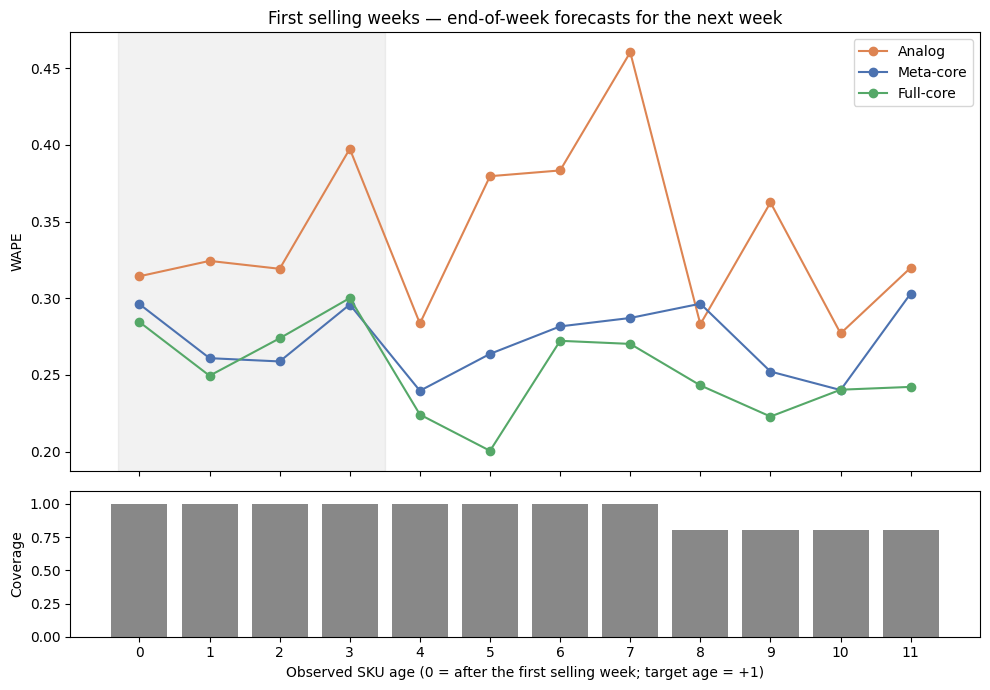

In [11]:
early_age_scores = scores_early[scores_early.window.str.match(r'^age \d+$')].copy()
early_age_scores['sku_age'] = early_age_scores.window.str.replace('age ', '').astype(int)
fig, (ax, coverage_ax) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                                    gridspec_kw={'height_ratios': [3, 1]})
for model, color in [('Analog', '#DD8452'), ('Meta-core', '#4C72B0'), ('Full-core', '#55A868')]:
    part = early_age_scores[early_age_scores.model == model]
    ax.plot(part.sku_age, part.WAPE, marker='o', label=model, color=color)
ax.axvspan(-0.3, 3.5, color='gray', alpha=0.10)
ax.set_ylabel('WAPE')
ax.set_title('First selling weeks — end-of-week forecasts for the next week')
ax.legend()
coverage_ax.bar(coverage_early.sku_age, coverage_early.coverage, color='#888888')
coverage_ax.set_ylim(0, 1.1)
coverage_ax.set_ylabel('Coverage')
coverage_ax.set_xlabel('Observed SKU age (0 = after the first selling week; target age = +1)')
coverage_ax.set_xticks(range(12))
plt.tight_layout()
plt.savefig('../../reports/figures/phase10_early_history_curve.png', dpi=120)
plt.show()


## 9. ข้อค้นพบช่วงอายุ 0–3

- ประเมิน 179 แถวจาก 5 SKU: อายุ 0 มี 44 แถว อายุ 1–3 มีอย่างละ 45 แถว ทั้งสามวิธีมี coverage 100% ในช่วงนี้
- WAPE รวม: Analog 33.84%, Meta-core 27.77%, Full-core 27.68% สองโมเดล ML ใกล้กันมาก (ต่างประมาณ 0.09 จุดเปอร์เซ็นต์) ไม่มีหลักฐานว่าตัวใดชนะอย่างมีนัยสำคัญ
- ผลแยก SKU ต่างกัน: Meta-core ดีกว่าสำหรับ MI-008 และ YO-018 ส่วน Full-core ดีกว่าสำหรับ SN-028, SN-030 และ YO-024
- รอบ core-only เดียวกัน อายุ 4–11 บนแถวร่วม: Meta-core 27.22% และ Full-core 24.04% สอดคล้องกับประโยชน์ของการมีประวัติเพิ่ม แต่ยังไม่ใช่หลักฐานเชิงสาเหตุว่าอายุเป็นปัจจัยเดียว
- `observed_days` นับวันที่มี record ของแต่ละ SKU/channel/region สัปดาห์อายุ 0 อาจไม่เต็มสัปดาห์ และจำนวนวันที่มี record น้อยกว่า 7 ในสัปดาห์อื่นก็พบได้ ไม่ได้พิสูจน์ว่าวันที่ไม่มี record เป็นยอดขายศูนย์หรือข้อมูลหาย
- ตารางใหม่มีแถวอายุ 4 เพิ่มหนึ่งแถวที่ pipeline เดิมตัดออก เพราะ channel นั้นมีประวัติไม่ครบ จึงห้ามถือว่าตารางใหม่เหมือนตารางเดิมทุกแถว
- ยังไม่ทดสอบการพยากรณ์ก่อนเริ่มขาย: ทุกแถวใช้ units_sold และข้อมูลจริงของสัปดาห์ปัจจุบัน ณ เมื่อจบสัปดาห์ เพื่อทำนายสัปดาห์ถัดไป

ไฟล์ตรวจย้อนหลังอยู่ใน reports/phase10/: คะแนนรายอายุ/ช่วงอายุ, coverage, คะแนนราย SKU และ predictions ช่วงอายุ 0–11


## 10. ก่อนเปิดตัว: ไม่มีประวัติยอดขายของสินค้าเป้าหมาย

**โจทย์ใหม่:** ณ ก่อนเริ่มสัปดาห์เปิดตัว ทำนายยอดขายรวมที่บันทึกในสัปดาห์เปิดตัวนั้น
(จันทร์–อาทิตย์) สัปดาห์แรกอาจขายไม่ครบ 7 วัน ไม่ใช่ยอดขาย 7 วันเต็มนับจากวันเปิดตัว
เป็นคนละ target กับส่วนก่อนหน้า ซึ่งใช้ยอดขายสัปดาห์ปัจจุบันเพื่อทำนายสัปดาห์ถัดไป

ใช้ LightGBM แบบ **Zero-history** และ Analog แบบไม่ใช้ราคา
ฟีเจอร์ ML มีเฉพาะ category/segment/brand/channel/region และ month/week_number/year
ไม่มี units_sold, lag, rolling, observed_days, ราคา โปรโมชั่น stock หรือ delivery จริงของสินค้าใหม่
Full-core กับ Meta-core ต่างกันเพราะประวัติขาย เมื่อไม่มีประวัติทั้งคู่จึงไม่มีเหตุผลให้แยกชื่อสองวิธี

**ข้อสมมติสำคัญ:** ชุดข้อมูลไม่มีตารางแผนเปิดตัว แผนราคา แผนโปรโมชั่น หรือ assortment ล่วงหน้า
วันเปิดตัวและช่องทาง/พื้นที่ที่นำมาทดสอบจึงอนุมานย้อนหลังจากข้อมูลขายจริง
โดยสมมติว่าผู้วางแผนรู้ schedule/metadata เหล่านี้ก่อนเปิดตัว การทดลองจึงเป็น
**conditional retrospective zero-history** ไม่ใช่หลักฐานว่ามีข้อมูลแผนล่วงหน้าจริงครบถ้วน
ไม่สร้าง combination ที่ไม่มี record ให้เป็นยอดขายศูนย์ รายงานขอบเขตนี้แยกจาก coverage ของโมเดล

ฝึกเฉพาะยอดขายสัปดาห์เปิดตัวของ SKU อื่นที่สิ้นสุดก่อน cutoff ของสินค้าเป้าหมาย
กันทั้ง 5 SKU ทดสอบออกจาก train ทุกครั้ง Analog ใช้ channel/region เดียวกัน
เลือกหมวด/segment/brand ใกล้สุด แล้ว tie-break ด้วย launch ล่าสุดที่ label ครบและรหัส SKU
ไม่ใช้ราคาเป้าหมายหลังเริ่มขายมาช่วยเลือก และไม่ใช้ยอดขายเป้าหมายเป็น input


In [12]:
from models.zero_history import build_launch_records, zero_history_forecast, ZERO_HISTORY_FEATURES
import hashlib
import json
import platform
import lightgbm
from models.forecast import DEFAULT_LGB_PARAMS

zero_records = build_launch_records(launch_daily)
zero_predictions = zero_history_forecast(zero_records, COLD_START_SKUS)
assert (zero_predictions.train_label_available_max <= zero_predictions.train_cutoff).all()
assert (zero_predictions.dropna(subset=['pred_zero_analog']).analog_label_available_at <=
        zero_predictions.dropna(subset=['pred_zero_analog']).train_cutoff).all()
assert not {'launch_units', 'units_sold', 'price_unit', 'promotion_flag', 'observed_days'} & set(ZERO_HISTORY_FEATURES)
assert np.isfinite(zero_predictions.pred_zero_lgb).all()
print('Zero-history features:', ZERO_HISTORY_FEATURES)
print('Evaluation rows:', len(zero_predictions), 'from', zero_predictions.sku.nunique(), 'SKUs')
display(zero_predictions[['sku', 'week', 'train_rows', 'train_skus', 'train_label_available_max', 'train_cutoff']].drop_duplicates())
display(zero_predictions.groupby('sku').agg(n=('sku', 'size'),
    observed_days_min=('observed_days', 'min'), observed_days_max=('observed_days', 'max')))

zero_common = zero_predictions.dropna(subset=['pred_zero_lgb', 'pred_zero_analog'])
zero_scores = []
for scope, part, methods in [
    ('common rows', zero_common, [('Analog no-price', 'pred_zero_analog'), ('Zero-history LightGBM', 'pred_zero_lgb')]),
    ('all ML rows', zero_predictions, [('Zero-history LightGBM', 'pred_zero_lgb')])]:
    for model, col in methods:
        zero_scores.append({'model': model, 'scope': scope, 'n': len(part),
            'available_n': len(zero_predictions), 'coverage': len(part)/len(zero_predictions),
            **score_all(part.launch_units, part[col])})
zero_summary = pd.DataFrame(zero_scores)
display(zero_summary.round(4))

zero_by_sku = []
for sku, available in zero_predictions.groupby('sku'):
    part = zero_common[zero_common.sku == sku]
    for model, col in [('Analog no-price', 'pred_zero_analog'), ('Zero-history LightGBM', 'pred_zero_lgb')]:
        zero_by_sku.append({'sku': sku, 'model': model, 'n': len(part), 'available_n': len(available),
            'coverage': len(part)/len(available), **score_all(part.launch_units, part[col])})
zero_by_sku = pd.DataFrame(zero_by_sku)
display(zero_by_sku.round(4))

zero_predictions.to_csv(output_dir / 'zero_history_predictions.csv', index=False)
zero_summary.to_csv(output_dir / 'zero_history_scores.csv', index=False)
zero_by_sku.to_csv(output_dir / 'zero_history_by_sku.csv', index=False)
zero_manifest = {
    'protocol': 'conditional retrospective metadata-only prelaunch forecast',
    'target': 'recorded SKU/channel/region units during launch calendar week (may be partial)',
    'schedule_source': 'first observed week and active combinations inferred retrospectively; assumed known',
    'features': ZERO_HISTORY_FEATURES, 'held_out_skus': COLD_START_SKUS,
    'training_rule': 'other SKUs launch weeks with label_available_at <= target launch Monday',
    'input_file': 'data/interim/daily_validated.csv',
    'input_sha256': hashlib.sha256(Path('../../data/interim/daily_validated.csv').read_bytes()).hexdigest(),
    'python_version': platform.python_version(), 'pandas_version': pd.__version__,
    'lightgbm_version': lightgbm.__version__, 'lightgbm_params': DEFAULT_LGB_PARAMS,
    'evaluation_rows': len(zero_predictions),
    'limitations': ['no verified prelaunch schedule or assortment', 'no planned price or promotion',
                   'no zero synthesis for absent combinations', 'first week length varies',
                   'only five held-out SKUs; no significance test']}
(output_dir / 'zero_history_manifest.json').write_text(json.dumps(zero_manifest, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')


Zero-history features: ['category', 'segment', 'brand', 'channel', 'region', 'month', 'week_number', 'year']
Evaluation rows: 44 from 5 SKUs


,sku,week,train_rows,train_skus,train_label_available_max,train_cutoff
212,YO-024,2023-04-03,203,24,2023-03-13,2023-04-03
221,MI-008,2023-04-10,212,25,2023-04-10,2023-04-10
230,SN-028,2023-04-17,212,25,2023-04-10,2023-04-17
239,YO-018,2023-05-01,212,25,2023-04-10,2023-05-01
247,SN-030,2023-05-22,212,25,2023-04-10,2023-05-22


,n,observed_days_min,observed_days_max
sku,,,
MI-008,9,4,5
SN-028,9,3,4
SN-030,9,1,3
YO-018,8,1,1
YO-024,9,4,5


,model,scope,n,available_n,coverage,MAE,RMSE,WAPE,SMAPE
0,Analog no-price,common rows,44,44,1.0,33.5682,43.8792,0.5752,0.7298
1,Zero-history LightGBM,common rows,44,44,1.0,38.0546,51.1388,0.6520,0.7356
2,Zero-history LightGBM,all ML rows,44,44,1.0,38.0546,51.1388,0.6520,0.7356


,sku,model,n,available_n,coverage,MAE,RMSE,WAPE,SMAPE
0,MI-008,Analog no-price,9,9,1.0,22.0000,29.4468,0.3056,0.3194
1,MI-008,Zero-history LightGBM,9,9,1.0,16.0473,21.8165,0.2229,0.2268
2,SN-028,Analog no-price,9,9,1.0,28.2222,32.9140,0.5935,0.7979
3,SN-028,Zero-history LightGBM,9,9,1.0,15.9324,19.6521,0.3350,0.3194
4,SN-030,Analog no-price,9,9,1.0,26.0000,29.8366,0.5969,0.7826
5,SN-030,Zero-history LightGBM,9,9,1.0,21.3441,25.7201,0.4900,0.4383
6,YO-018,Analog no-price,8,8,1.0,17.1250,25.1818,0.7211,0.5882
7,YO-018,Zero-history LightGBM,8,8,1.0,45.2735,48.1296,1.9063,1.0622
8,YO-024,Analog no-price,9,9,1.0,72.6667,77.5156,0.7187,1.1451
9,YO-024,Zero-history LightGBM,9,9,1.0,92.4776,95.9299,0.9146,1.6676


1384

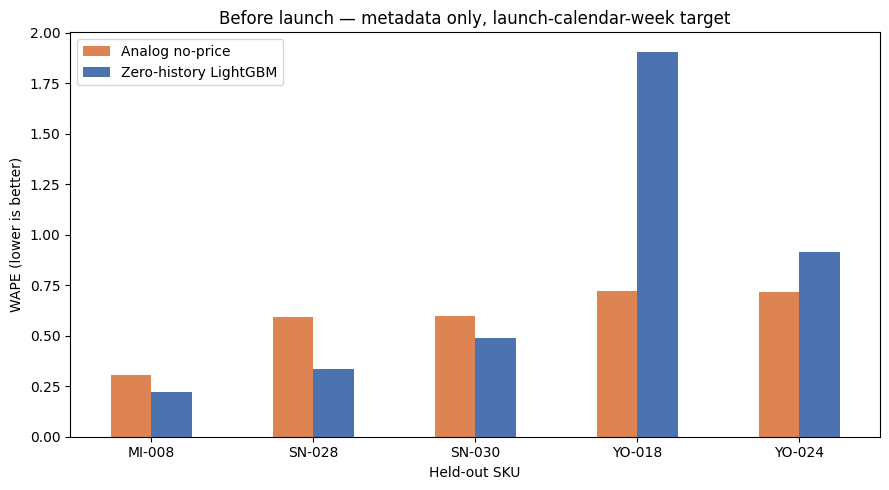

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
zero_chart = zero_by_sku.pivot(index='sku', columns='model', values='WAPE')
zero_chart.plot.bar(ax=ax, color=['#DD8452', '#4C72B0'])
ax.set_ylabel('WAPE (lower is better)')
ax.set_xlabel('Held-out SKU')
ax.set_title('Before launch — metadata only, launch-calendar-week target')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='')
plt.tight_layout()
plt.savefig('../../reports/figures/phase10_zero_history_comparison.png', dpi=120)
plt.show()


## 11. ผลและขอบเขตของการทดลองก่อนเปิดตัว

- ทดสอบ 44 แถว จาก 5 SKU (4 SKU มี 9 channel/region และ YO-018 มี 8) ทั้งสองวิธีมี prediction ครบทุกแถวที่อยู่ในชุดประเมิน ไม่ได้แปลว่าครอบคลุม assortment ที่ไม่ปรากฏในข้อมูล
- Analog แบบไม่ใช้ราคา: WAPE **57.52%**; LightGBM แบบไม่มีประวัติ: **65.20%** Analog ต่ำกว่าในผลรวมรอบนี้ แต่ยังผิดพลาดสูง ไม่มีวิธีใดควรถูกอ้างว่าพร้อม production
- ML ดีกว่าใน MI-008, SN-028 และ SN-030; Analog ดีกว่าใน YO-018 และ YO-024 จึงไม่มีวิธีเดียวชนะทุก SKU และยังไม่มีการทดสอบนัยสำคัญ
- คะแนนนี้เทียบตรงกับ Full-core/Meta-core 27.7% ไม่ได้ เพราะคนละ target และข้อมูล ณ วันทำนาย: รอบนี้ทำนายสัปดาห์เปิดตัวก่อนมีประวัติ ส่วนรอบก่อนทำนายสัปดาห์ถัดไปหลังเห็นยอดขายแล้ว
- สัปดาห์เปิดตัวอาจสั้น เช่น SKU ที่เริ่มวันอาทิตย์มีช่วงเป้าหมายเพียงวันเดียว; feature set นี้ไม่ได้ปรับจำนวนวันขายตามแผน ความต่างนี้อาจมีส่วนต่อ error แต่ยังไม่ได้ทดลองแยกผล
- แผนวันเปิดตัว ช่องทาง/พื้นที่ และ metadata ก่อนเปิดตัวไม่ได้มีเอกสารเวลาใน dataset จึงยังเป็นผล **ภายใต้สมมติฐานว่ารู้ schedule/assortment ล่วงหน้า** แม้ไม่มียอดขายของ SKU เป้าหมายเป็นฟีเจอร์
- ส่วน 12 เพิ่มเป้าหมาย 7 วันแรกแล้ว; ยังต้องหา launch plan ที่มี timestamp จริงเพื่อยืนยันสมมติฐาน schedule/assortment ก่อนอ้างความพร้อมใช้งาน

บันทึก predictions, คะแนนรวม/ราย SKU และ manifest ที่ระบุ feature list, input checksum, parameters และข้อสมมติไว้ใน reports/phase10/zero_history_* แล้ว


## 12. ก่อนเปิดตัว: เป้าหมาย 7 วันแรกเท่ากัน และตัวเทียบค่าเฉลี่ย

ทุก SKU ใช้ช่วง [วันแรกที่พบ record, วันแรก+7 วัน) ไม่หยุดที่วันอาทิตย์
เช่น เปิดวันพุธ จะนับพุธ–อังคาร ต่างจากส่วน 10–11 ที่ใช้สัปดาห์ปฏิทิน
`week` ใน ledger รอบนี้หมายถึงวันเริ่มหน้าต่าง 7 วัน ไม่จำเป็นต้องเป็นวันจันทร์
ใช้ cutoff เป็นวันเริ่มนี้ โดย train รับเฉพาะ launch windows ของสินค้าอื่นที่ครบ 7 วันแล้ว
กันทั้ง 5 SKU ทดสอบออกจาก train และไม่ปรับ parameters จากผลทดสอบ

สามวิธีใช้ข้อมูลพื้นฐานที่สมมติว่าทราบล่วงหน้าเหมือนกัน:
1. Analog ไม่ใช้ราคา: สินค้าต้นแบบหนึ่งตัวตาม channel/region และ category/segment/brand
2. Zero-history LightGBM: metadata และปฏิทินเท่านั้น ไม่มียอดขายสินค้าใหม่ ราคา โปรโมชั่น หรือประวัติ
3. Category mean: ค่าเฉลี่ย launch units ของสินค้าอื่นหมวด/channel/region เดียวกัน ถ้าไม่พบจะ fallback ไปหมวดเดียวกัน, channel/region เดียวกัน และ global ตามลำดับ พร้อมบันทึกระดับและจำนวน donor

ข้อจำกัดเดิมยังคงอยู่: วันเปิดตัวและ assortment อนุมานย้อนหลัง ไม่ใช่แผนที่ยืนยัน timestamp แล้ว
การมีหน้าต่าง 7 วันไม่ได้แปลว่ามี record ครบ 7 วันในทุก channel/region
ไม่เติมวันหรือ combination ที่ไม่มี record เป็นยอดขายศูนย์ ต้องอ่าน observed_days ประกอบ
และไม่ใช้ observed_days เป็นฟีเจอร์ ผลนี้ยังเป็นการจำลองภายใต้สมมติฐานว่ารู้ schedule/assortment


In [14]:
from models.zero_history import build_seven_day_launch_records

seven_records = build_seven_day_launch_records(launch_daily)
seven_predictions = zero_history_forecast(seven_records, COLD_START_SKUS, include_category_baseline=True)
seven_cols = [('Analog no-price', 'pred_zero_analog'), ('Zero-history LightGBM', 'pred_zero_lgb'),
              ('Category mean', 'pred_category_mean')]
assert ((seven_records.label_available_at - seven_records.week).dt.days == 7).all()
assert (seven_predictions.train_label_available_max <= seven_predictions.train_cutoff).all()
seven_donors = seven_predictions.dropna(subset=['pred_zero_analog'])
assert (seven_donors.analog_label_available_at <= seven_donors.train_cutoff).all()
assert np.isfinite(seven_predictions[['pred_zero_lgb', 'pred_category_mean']].to_numpy()).all()
assert not seven_predictions.duplicated(['sku', 'channel', 'region']).any()

seven_common = seven_predictions.dropna(subset=[col for _, col in seven_cols])
seven_rows = []
for scope, part, methods in [('common rows', seven_common, seven_cols),
    ('all ML/baseline rows', seven_predictions, seven_cols[1:])]:
    for model, col in methods:
        seven_rows.append({'model': model, 'scope': scope, 'n': len(part),
            'available_n': len(seven_predictions), 'coverage': len(part)/len(seven_predictions),
            **score_all(part.launch_units, part[col])})
seven_summary = pd.DataFrame(seven_rows)
display(seven_summary.round(4))

seven_sku_rows = []
for sku, available in seven_predictions.groupby('sku'):
    part = seven_common[seven_common.sku == sku]
    for model, col in seven_cols:
        seven_sku_rows.append({'sku': sku, 'model': model, 'n': len(part),
            'available_n': len(available), 'coverage': len(part)/len(available),
            **score_all(part.launch_units, part[col])})
seven_by_sku = pd.DataFrame(seven_sku_rows)
display(seven_by_sku.round(4))
display(seven_predictions.groupby('sku').agg(n=('sku', 'size'),
    window_start=('week', 'min'), window_end_exclusive=('label_available_at', 'max'),
    observed_days_min=('observed_days', 'min'), observed_days_max=('observed_days', 'max')))
display(seven_predictions.groupby(['sku', 'baseline_level']).agg(
    rows=('sku', 'size'), min_donors=('baseline_donors', 'min'), max_donors=('baseline_donors', 'max')))
display(seven_predictions[['sku', 'train_cutoff', 'train_label_available_max', 'train_rows', 'train_skus']].drop_duplicates())

seven_predictions.to_csv(output_dir / 'seven_day_predictions.csv', index=False)
seven_summary.to_csv(output_dir / 'seven_day_scores.csv', index=False)
seven_by_sku.to_csv(output_dir / 'seven_day_by_sku.csv', index=False)
seven_manifest = dict(zero_manifest)
seven_manifest.update({
    'protocol': 'conditional metadata-only prelaunch forecast, seven calendar days from SKU first observation',
    'target': 'recorded units during [first_seen, first_seen + 7 days)',
    'training_rule': 'other non-held-out SKUs whose seven-day label is complete at target first_seen',
    'schedule_source': 'SKU first observation and active combinations in first 7 days inferred retrospectively',
    'evaluation_rows': len(seven_predictions),
    'baseline': 'mean category/channel/region; fallback category, channel/region, global',
    'limitations': ['no verified prelaunch schedule or assortment', 'no planned price or promotion',
        'missing daily records not imputed; observed_days is audit only',
        'only five held-out SKUs; no significance test',
        'different target and potentially different rows/cutoffs from calendar-week and short-history experiments']})
_ = (output_dir / 'seven_day_manifest.json').write_text(json.dumps(seven_manifest, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')


,model,scope,n,available_n,coverage,MAE,RMSE,WAPE,SMAPE
0,Analog no-price,common rows,45,45,1.0,38.0000,45.9270,0.3271,0.3758
1,Zero-history LightGBM,common rows,45,45,1.0,40.7147,51.0106,0.3505,0.3884
2,Category mean,common rows,45,45,1.0,30.0309,37.1545,0.2585,0.2733
3,Zero-history LightGBM,all ML/baseline rows,45,45,1.0,40.7147,51.0106,0.3505,0.3884
4,Category mean,all ML/baseline rows,45,45,1.0,30.0309,37.1545,0.2585,0.2733


,sku,model,n,available_n,coverage,MAE,RMSE,WAPE,SMAPE
0,MI-008,Analog no-price,9,9,1.0,25.1111,34.2377,0.2646,0.3035
1,MI-008,Zero-history LightGBM,9,9,1.0,18.7464,24.2826,0.1976,0.2033
2,MI-008,Category mean,9,9,1.0,18.0000,23.6150,0.1897,0.1942
3,SN-028,Analog no-price,9,9,1.0,27.7778,36.7272,0.2809,0.3239
4,SN-028,Zero-history LightGBM,9,9,1.0,27.4816,31.0254,0.2779,0.2939
5,SN-028,Category mean,9,9,1.0,29.2500,33.8814,0.2958,0.3193
6,SN-030,Analog no-price,9,9,1.0,40.4444,48.0208,0.3583,0.4402
7,SN-030,Zero-history LightGBM,9,9,1.0,36.5461,44.1098,0.3237,0.3662
8,SN-030,Category mean,9,9,1.0,32.9167,40.7316,0.2916,0.3237
9,YO-018,Analog no-price,9,9,1.0,39.2222,42.3858,0.2898,0.3012


,n,window_start,window_end_exclusive,observed_days_min,observed_days_max
sku,,,,,
MI-008,9,2023-04-12,2023-04-19,6,7
SN-028,9,2023-04-20,2023-04-27,5,7
SN-030,9,2023-05-26,2023-06-02,5,7
YO-018,9,2023-05-07,2023-05-14,4,7
YO-024,9,2023-04-05,2023-04-12,5,7


,,rows,min_donors,max_donors
sku,baseline_level,,,
MI-008,category_channel_region,9,6,6
SN-028,category_channel_region,9,4,4
SN-030,category_channel_region,9,4,4
YO-018,category_channel_region,9,9,9
YO-024,category_channel_region,9,9,9


,sku,train_cutoff,train_label_available_max,train_rows,train_skus
225,YO-024,2023-04-05,2023-03-19,216,24
234,MI-008,2023-04-12,2023-04-11,225,25
243,SN-028,2023-04-20,2023-04-11,225,25
252,YO-018,2023-05-07,2023-04-11,225,25
261,SN-030,2023-05-26,2023-04-11,225,25


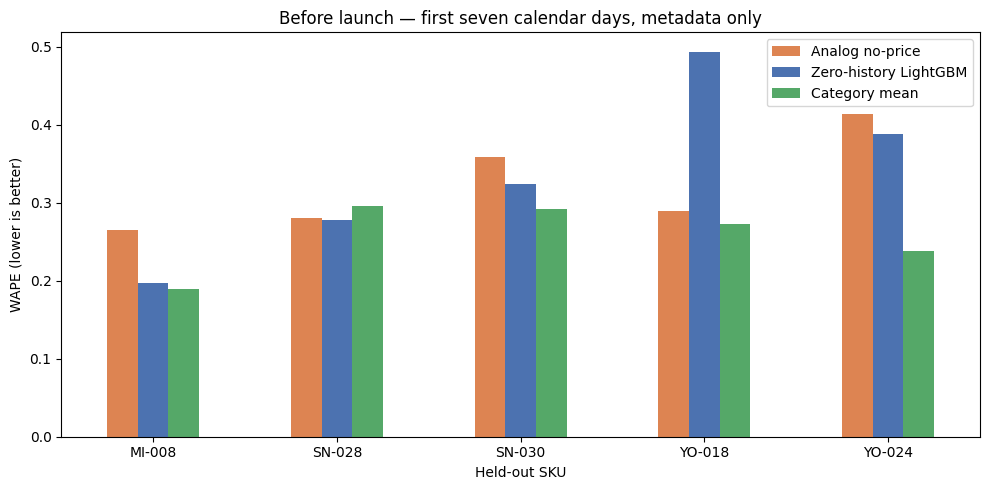

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
seven_chart = seven_by_sku.pivot(index='sku', columns='model', values='WAPE')
seven_chart = seven_chart[['Analog no-price', 'Zero-history LightGBM', 'Category mean']]
seven_chart.plot.bar(ax=ax, color=['#DD8452', '#4C72B0', '#55A868'])
ax.set_ylabel('WAPE (lower is better)')
ax.set_xlabel('Held-out SKU')
ax.set_title('Before launch — first seven calendar days, metadata only')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='')
plt.tight_layout()
plt.savefig('../../reports/figures/phase10_seven_day_comparison.png', dpi=120)
plt.show()


## 13. ข้อค้นพบจากเป้าหมาย 7 วันแรก

- ทั้งสามวิธีทดสอบบน 45 แถวเดียวกันจาก 5 SKU (SKU ละ 9 channel/region) coverage 100% ของชุดที่สร้างขึ้น ไม่ใช่ของทุก assortment ที่อาจมีในโลกจริง
- WAPE: **Category mean 25.85%**, Analog 32.71%, Zero-history LightGBM 35.05% ค่าเฉลี่ยหมวด/channel/region เดียวกันดีที่สุดในภาพรวมของการทดลองนี้
- Category mean ดีกว่าอีกสองวิธีใน 4 จาก 5 SKU; SN-028 LightGBM ต่ำที่สุด จึงไม่ควรเหมารวมว่าค่าเฉลี่ยชนะทุกสินค้า และยังไม่มีการทดสอบนัยสำคัญ
- Baseline ใช้หมวด/channel/region เดียวกันได้ครบทุกแถว โดยมี donor 4–9 รายการต่อแถว จึงไม่มีการ fallback ในข้อมูลจริงรอบนี้ แต่โค้ดบันทึก fallback เมื่อจำเป็น
- คะแนนต่ำกว่ารอบสัปดาห์ปฏิทิน แต่ target, cutoff และชุดแถวต่างกัน (รอบเดิม 44 แถว รอบนี้ 45) จึงไม่ควรอ้างว่า accuracy ดีขึ้นกี่เปอร์เซ็นต์จากการปรับโมเดล
- สำหรับข้อมูลที่มี ก่อนเปิดตัวควรเก็บค่าเฉลี่ยหมวด/channel/region เป็น baseline หลักที่โมเดลซับซ้อนต้องชนะ ไม่จำเป็นต้องเลือก ML เพราะชื่อวิธี
- ผลนี้ยังเป็น conditional retrospective evaluation: รู้วันเปิดตัว/assortment โดยสมมติจากข้อมูลย้อนหลัง และไม่มีแผนราคา/โปรโมชั่นจริงก่อนเปิดตัว
- แม้หน้าต่างยาวเท่ากัน แต่ observed_days ของแถวจริงอยู่ที่ 4–7 วัน อาจมีทั้งการเริ่มช่องทางช้าหรือไม่มี record; ไม่ได้พิสูจน์ว่าวันที่ไม่มี record ขายได้ศูนย์
- งานต่อไปที่มีประโยชน์คือยืนยัน launch plans และเพิ่มจำนวน SKU ที่ใช้ทดสอบ ก่อนปรับ hyperparameters ด้วยชุด validation ที่แยกจาก 5 SKU เหล่านี้

เก็บ predictions, คะแนนรวม/ราย SKU และ manifest ใน reports/phase10/seven_day_* พร้อมกราฟ phase10_seven_day_comparison.png ผลเดิมทุก protocol ยังอยู่แยกกัน
